# 06 — Modelagem da Fila (Mempool), Tempo de Espera e Previsão de Taxas

Este notebook expande o pipeline econométrico desenvolvido nos cadernos `04_Preparacao_Modelagem` e `05_Modelagem_Taxas_e_Avaliacao`, integrando **dados reais de fila (*mempool*) e tempo de espera/latência de confirmação** da rede Bitcoin coletados via API da Blockchain.com para o histórico completo de 2 anos (17.520 horas).

---

## O Diagnóstico dos Cadernos Anteriores e o Papel da Fila Real

| Diagnóstico nos Cadernos 04 e 05 | Limitação Teórica / Física | O que este Notebook 06 implementa |
|---|---|---|
| A ocupação de bloco do BTC satura em **~99,85%** (IQR 99,83%–99,86%) | Os blocos estão sempre cheios porque mineradores preenchem com transações de satoshis irrisórios; **a ocupação de bloco não mede a pressão de demanda** | Substitui a ocupação de bloco pela **profundidade real da Mempool** (bytes acumulados, contagem de transações e razão de chegada). |
| O BigQuery só contém blocos já minerados e confirmados | Isso é a "saída da fábrica"; não tínhamos a medição da **sala de espera** nem do **tempo de espera** | Incorpora a série histórica de 750 dias de **tempo médio de confirmação (`avg-confirmation-time`)** e tamanho da fila. |
| O estado da própria taxa ($B_1$) foi responsável por 90%+ do poder preditivo | O mercado financeiro (RV e retornos) não agregou ganho incremental ao estado da taxa | Testa formalmente: **A fila real da mempool possui valor preditivo causal além do estado da própria taxa?** |

---

## Periodicidade e Resolução Temporal dos Dados da API

> **Frequência dos Dados Brutos:**
> - **Tamanho da Fila (`mempool-size`):** Amostrado a cada **15 minutos** (4 pontos por hora, ~72.000 registros em 750 dias).
> - **Contagem de Transações Pendentes (`mempool-count`):** Amostrado a cada **15 minutos**.
> - **Taxa de Chegada de Dados (`mempool-growth`):** Amostrado a cada **15 minutos** (Bytes/segundo).
> - **Tempo Médio de Confirmação (`avg-confirmation-time`):** Amostrado a cada **24 horas** (resolução diária, ~747 registros).
>
> **Consolidação Causal na Grade de 1 Hora:**
> - As séries de 15 minutos são agregadas calculando a média móvel horária (`_media`) e o snapshot de fechamento da hora (`_fim`).
> - A série diária de tempo de confirmação é inserida com **defasagem estrita de 24 horas (`lag 24h`)**, garantindo que nenhum dado do dia seguinte contamine a decisão horária.

---

## Regras de Rigor Mantidas
1. Validação temporal estrita: **Walk-Forward com 8 dobras** no período de desenvolvimento (`dev`, 14.616 horas) e **embargo de 24 horas** entre treino e teste.
2. O *Holdout* (últimos 90 dias) permanece **congelado e fechado sob trava criptográfica**.
3. Toda feature nova é causal e validada por **teste de perturbação** com injeção de ruído.
4. Testes de significância formal: **Diebold-Mariano com correção HAC (Newey-West)**, **Bootstrap em blocos de 48h** e **correção de Holm** para controle de taxa de falso positivo.

In [ ]:
from pathlib import Path
import json
import time
import urllib.request
import pandas as pd

PASTA_BASE = Path("/home/alisson/datathon fgv")
PASTA_MEMPOOL = PASTA_BASE / "dados_cripto" / "mempool"
PASTA_MEMPOOL.mkdir(parents=True, exist_ok=True)

# 1. Endpoints dos 4 gráficos históricos da Blockchain.com (750 dias)
CHARTS = {
    "mempool_size_bytes": "mempool-size",
    "mempool_count_tx": "mempool-count",
    "mempool_growth_bps": "mempool-growth",
    "avg_confirmation_time_min": "avg-confirmation-time",
}

dfs = {}

# 2. Download com persistência de cache JSON
for col_name, slug in CHARTS.items():
  json_path = PASTA_MEMPOOL / f"{slug}_750days.json"

  if json_path.exists():
    print(f"Lendo do cache local: {json_path}")
    with open(json_path, "r", encoding="utf-8") as f:
      data = json.load(f)
  else:
    url = f"https://api.blockchain.info/charts/{slug}?timespan=750days&format=json&sampled=false"
    print(f"Baixando {slug} de {url}...")
    req = urllib.request.Request(
        url, headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
    )
    with urllib.request.urlopen(req, timeout=30) as resp:
      data = json.loads(resp.read().decode())
    with open(json_path, "w", encoding="utf-8") as f:
      json.dump(data, f)
    print(f"Salvo {json_path.name} com sucesso.")

  # Parsing temporal para UTC
  vals = data.get("values", [])
  df = pd.DataFrame(vals)
  df["hora"] = pd.to_datetime(df["x"], unit="s", utc=True)
  df = df.rename(columns={"y": col_name})[["hora", col_name]].sort_values(
      "hora"
  )
  dfs[col_name] = df

# 3. Agregação das séries de 15 minutos (size, count, growth) para grade de 1 hora
df_15m = dfs["mempool_size_bytes"].merge(
    dfs["mempool_count_tx"], on="hora", how="outer"
)
df_15m = df_15m.merge(
    dfs["mempool_growth_bps"], on="hora", how="outer"
).sort_values("hora")

df_15m["hora_1h"] = df_15m["hora"].dt.floor("1h")
agg_1h = (
    df_15m.groupby("hora_1h")
    .agg(
        btc_mempool_bytes_media=("mempool_size_bytes", "mean"),
        btc_mempool_bytes_fim=("mempool_size_bytes", "last"),
        btc_mempool_count_media=("mempool_count_tx", "mean"),
        btc_mempool_count_fim=("mempool_count_tx", "last"),
        btc_mempool_growth_bps_media=("mempool_growth_bps", "mean"),
    )
    .reset_index()
    .rename(columns={"hora_1h": "hora"})
)

# 4. Sincronização da série diária de tempo médio de confirmação (avg-confirmation-time)
df_conf = dfs["avg_confirmation_time_min"].copy()
df_conf["hora_1h"] = df_conf["hora"].dt.floor("1h")
df_conf = (
    df_conf.drop(columns=["hora"])
    .drop_duplicates(subset=["hora_1h"])
    .rename(
        columns={
            "hora_1h": "hora",
            "avg_confirmation_time_min": "btc_avg_conf_time_min",
        }
    )[["hora", "btc_avg_conf_time_min"]]
)

df_mempool_1h = agg_1h.merge(df_conf, on="hora", how="left")
df_mempool_1h["btc_avg_conf_time_min"] = df_mempool_1h[
    "btc_avg_conf_time_min"
].ffill()

# 5. Salva a base horária consolidada
saida_csv = PASTA_MEMPOOL / "blockchain_mempool_horario_2anos.csv"
df_mempool_1h.to_csv(saida_csv, index=False)

In [1]:
from pathlib import Path
import json, warnings, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

try:
    from sklearn.ensemble import HistGradientBoostingClassifier
    TEM_SKLEARN = True
except ImportError:
    TEM_SKLEARN = False
    print("scikit-learn não encontrado: modelo HistGradientBoosting será pulado.")

# ------------------- CAMINHOS -------------------
PASTA_BASE = Path("/home/alisson/datathon fgv")
PASTA_DADOS = PASTA_BASE / "Análises"
PASTA_MODELAGEM = PASTA_DADOS / "modelagem"          # saídas do notebook 04
PASTA_MEMPOOL = PASTA_BASE / "dados_cripto" / "mempool"
PASTA_SAIDA = PASTA_MODELAGEM / "06"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
PASTA_MEMPOOL.mkdir(parents=True, exist_ok=True)

# ------------------- PARÂMETROS -------------------
HORIZONTES_TAXA = [1, 6]
H_PRAZO = 6                      # prazo máximo de espera operacional (horas)
TAXAS_ALERTA = [0.05, 0.10, 0.20]
L2_LOGIT = 1.0
B_BOOT = 500
BLOCO_H = 48
SEMENTE = 42
rng = np.random.default_rng(SEMENTE)

# ------------------- HOLDOUT: TRAVA -------------------
ABRIR_HOLDOUT = False            # mantido estritamente congelado
print(f"Configuração carregada | sklearn: {TEM_SKLEARN} | Pasta saída: {PASTA_SAIDA}")

scikit-learn não encontrado: modelo HistGradientBoosting será pulado.
Configuração carregada | sklearn: False | Pasta saída: /home/alisson/datathon fgv/Análises/modelagem/06


## 1. Carga e Fusão dos Dados de Fila (Blockchain.com 2 Anos)

Carrega o dataset base de modelagem (`dataset_modelagem.csv`, 17.520 horas), a grade de *folds* da validação *walk-forward* e a série horária de mempool consolidada a partir dos registros de 15 minutos da Blockchain.com.

In [2]:
# 1. Carrega o dataset de modelagem e folds
df_all = pd.read_csv(PASTA_MODELAGEM / "dataset_modelagem.csv")
df_all["hora"] = pd.to_datetime(df_all["hora"], utc=True).astype("datetime64[ns, UTC]")
df_all = df_all.sort_values("hora").reset_index(drop=True)

folds_df = pd.read_csv(PASTA_MODELAGEM / "folds_walkforward.csv")
folds = folds_df[["tr_ini", "tr_fim", "te_ini", "te_fim"]].to_dict("records")

# 2. Carrega ou gera a série horária de mempool
ARQ_MEMPOOL = PASTA_MEMPOOL / "blockchain_mempool_horario_2anos.csv"
if not ARQ_MEMPOOL.exists():
    raise FileNotFoundError(f"Arquivo de mempool não encontrado em {ARQ_MEMPOOL}. Execute a coleta prévia.")

df_mem = pd.read_csv(ARQ_MEMPOOL)
df_mem["hora"] = pd.to_datetime(df_mem["hora"], utc=True).astype("datetime64[ns, UTC]")
df_mem = df_mem.sort_values("hora").reset_index(drop=True)

# 3. Merge causal one-to-one
n_antes = len(df_all)
cols_mem = [c for c in df_mem.columns if c != "hora"]
df_all = df_all.merge(df_mem[["hora"] + cols_mem], on="hora", how="left")
assert len(df_all) == n_antes, "Merge alterou o número de linhas do dataset!"

print(f"Dataset de modelagem carregado: {len(df_all):,} linhas (17.520 horas)")
print(f"Período: {df_all['hora'].min()} até {df_all['hora'].max()}")
print(f"Variáveis de fila incorporadas: {cols_mem}")
nulls_dict = df_all[cols_mem].isnull().sum().to_dict()
print(f"Valores nulos nas variáveis de mempool: {nulls_dict}")

Dataset de modelagem carregado: 17,520 linhas (17.520 horas)
Período: 2024-11-03 00:00:00+00:00 até 2026-11-02 23:00:00+00:00
Variáveis de fila incorporadas: ['btc_mempool_bytes_media', 'btc_mempool_bytes_fim', 'btc_mempool_count_media', 'btc_mempool_count_fim', 'btc_mempool_growth_bps_media', 'btc_avg_conf_time_min']
Valores nulos nas variáveis de mempool: {'btc_mempool_bytes_media': 0, 'btc_mempool_bytes_fim': 0, 'btc_mempool_count_media': 0, 'btc_mempool_count_fim': 0, 'btc_mempool_growth_bps_media': 0, 'btc_avg_conf_time_min': 0}


## 2. Engenharia de Recursos da Fila (Teoria de Filas) e Teste de Perturbação

Na Teoria de Filas clássica ($M/M/1$ ou $M/G/1$), o estado da fila não é medido por contadores absolutos não-estacionários, mas por:
1. **Profundidade em Unidades de Serviço ($vBlocks$):** $\frac{\text{Mempool Bytes}}{1.000.000}$, indicando quantos blocos completos de 1 MB seriam necessários para limpar a fila no momento presente.
2. **Desvio Relativo à Mediana Recente (`rel30d`):** Mede o estresse da fila em relação à capacidade operacional dos últimos 30 dias:
   $$\ln(\text{mempool\_vblocks}) - \ln(\text{mediana}_{30d})$$
3. **Aceleração da Fila (`chg6h`):** Taxa de expansão ou drenagem da fila nas últimas 6 horas.
4. **Velocidade Relativa de Chegada (`growth_rel`):** Taxa de injeção de novas transações em relação à média semanal.
5. **Tempo de Confirmação Relativo com Lag Causal (`conf_time_lag24h`):** Mede a latência observada das transações com defasagem de 24 horas, eliminando lookahead.
6. **Regimes Extremos:** Indicadores binários de *Fila Alta* ($> 5$ blocos acumulados) e *Fila Drenada* ($< 1$ bloco acumulado).

In [3]:
def log_pos(s):
    return np.log(s.where(s > 0))

def construir_features_mempool(df):
    d = df.copy()
    
    # 0. Estado da própria taxa e choques de mercado (alinhado com o notebook 05)
    x = d["btc_bq_taxa_p50_sat_vb"]
    ref = d["btc_taxa_ref_q"]
    d["btc_dist_ref_q"] = log_pos(x) - log_pos(ref)
    d["btc_em_evento"] = (x > ref).astype(float).where(x.notna() & ref.notna())
    d["btc_lrv_choque"] = d["btc_lrv"] - d["btc_lrv_w"]
    p90 = d["btc_bq_taxa_p90_sat_vb"]
    d["btc_lfee_p90_rel"] = log_pos(p90) - log_pos(p90.rolling(720, min_periods=360).median())
    
    # 1. Profundidade da fila em blocos equivalentes (1 MB padrão)
    vblocks = d["btc_mempool_bytes_media"] / 1e6
    d["btc_mempool_vblocks"] = vblocks
    
    # 2. Desvio relativo à mediana de 30 dias (720h)
    med_30d = vblocks.rolling(720, min_periods=360).median()
    d["btc_mempool_rel30d"] = np.log(vblocks.clip(lower=0.01)) - np.log(med_30d.clip(lower=0.01))
    
    # 3. Aceleração da fila em 6 horas
    d["btc_mempool_chg6h"] = np.log(vblocks.clip(lower=0.01)) - np.log(vblocks.shift(6).clip(lower=0.01))
    
    # 4. Taxa de chegada de dados relativa à média semanal (168h)
    gw = d["btc_mempool_growth_bps_media"].clip(lower=1.0)
    d["btc_mempool_growth_rel"] = np.log(gw) - np.log(gw.rolling(168, min_periods=84).mean())
    
    # 5. Tempo médio de confirmação diário com lag estrito de 24 horas (causalidade plena)
    ct = d["btc_avg_conf_time_min"]
    med_ct_30d = ct.rolling(720, min_periods=360).median()
    d["btc_conf_time_rel"] = np.log(ct.clip(lower=1.0)) - np.log(med_ct_30d.clip(lower=1.0))
    d["btc_conf_time_lag24h"] = d["btc_conf_time_rel"].shift(24)
    
    # 6. Indicadores de regimes operacionais da fila
    d["btc_fila_alta"] = (vblocks > 5.0).astype(float)       # fila com mais de 5 blocos represados
    d["btc_fila_drenada"] = (vblocks < 1.0).astype(float)    # fila com menos de 1 bloco (vazia)
    
    # Alvos adicionais de início de evento para a modelagem
    for h in HORIZONTES_TAXA:
        if f"y_btc_novo_{h}h" not in d.columns:
            ev = d[f"y_btc_ev_q_{h}h"]
            ref = d["btc_taxa_ref_q"]
            em_ev = (d["btc_bq_taxa_p50_sat_vb"] > ref).astype(float)
            d[f"y_btc_novo_{h}h"] = ev.where(em_ev == 0)
            
    return d

colunas_antes = set(df_all.columns)
df_all = construir_features_mempool(df_all)
novas_feat_mempool = [c for c in df_all.columns if c not in colunas_antes and not c.startswith("y_")]

# --- TESTE DE PERTURBAÇÃO CAUSAL ---
def teste_perturbacao(df, t0):
    d2 = df.copy()
    num_cols = list(d2.select_dtypes("number").columns)
    pos = [d2.columns.get_loc(c) for c in num_cols]
    d2.iloc[t0 + 1:, pos] = d2.iloc[t0 + 1:, pos].to_numpy() * rng.uniform(0.5, 2.0, size=(len(d2) - t0 - 1, len(pos)))
    
    base_cols = [c for c in df.columns if c not in novas_feat_mempool]
    f1 = construir_features_mempool(df[base_cols])
    f2 = construir_features_mempool(d2[base_cols])
    
    ruins = [c for c in novas_feat_mempool if not np.allclose(f1[c].iloc[:t0 + 1].to_numpy(float),
                                                               f2[c].iloc[:t0 + 1].to_numpy(float), equal_nan=True)]
    return ruins

t0 = len(df_all) // 2
vazadas = teste_perturbacao(df_all, t0)
print(f"Features de fila construídas: {len(novas_feat_mempool)} colunas: {novas_feat_mempool}")
print(f"Teste de perturbação causal em t0 = {df_all['hora'].iloc[t0]}: variáveis com vazamento = {vazadas}")
assert not vazadas, f"ALERTA DE VAZAMENTO CAUSAL: {vazadas}"

dev = df_all[df_all["particao"] == "dev"].reset_index(drop=True)
print("\nEstatísticas descritivas das novas variáveis de fila no conjunto DEV:")
display(dev[novas_feat_mempool].describe().T[["mean", "std", "min", "50%", "max"]].round(4))

Features de fila construídas: 12 colunas: ['btc_dist_ref_q', 'btc_em_evento', 'btc_lrv_choque', 'btc_lfee_p90_rel', 'btc_mempool_vblocks', 'btc_mempool_rel30d', 'btc_mempool_chg6h', 'btc_mempool_growth_rel', 'btc_conf_time_rel', 'btc_conf_time_lag24h', 'btc_fila_alta', 'btc_fila_drenada']
Teste de perturbação causal em t0 = 2025-11-03 00:00:00+00:00: variáveis com vazamento = []

Estatísticas descritivas das novas variáveis de fila no conjunto DEV:
                           mean      std     min     50%      max
btc_dist_ref_q          -0.9837   0.9000 -3.7641 -0.8473   2.1327
btc_em_evento            0.0876   0.2828  0.0000  0.0000   1.0000
btc_lrv_choque          -0.3061   0.5519 -2.7746 -0.3190   2.4313
btc_lfee_p90_rel        -0.0039   0.4254 -3.3322 -0.0274   3.4855
btc_mempool_vblocks     10.7162  19.6963  0.1239  1.3221  86.2464
btc_mempool_rel30d      -0.0182   1.0294 -4.6338 -0.0632   3.6892
btc_mempool_chg6h       -0.0001   0.8428 -3.4473  0.0036   3.5459
btc_mempool_growth_

## 3. Diagnóstico Econométrico da Fila

### 3.1 Estacionariedade e Tendência Secular (vs. Ocorrência Espúria)
No notebook 05, foi provado que o índice *Fear & Greed* apresentava correlação espúria com a taxa por ambas estarem em queda secular contra o tempo. Aqui testamos se a Mempool em nível ou tratada apresenta tendência espúria ou se captura ciclos econômicos genuínos de curto prazo.

### 3.2 Causalidade de Granger e Lift Preditivo
A fila antecipa estatisticamente a variação da taxa horária? E qual é o aumento relativo da probabilidade de pico de taxa quando a mempool está saturada?

In [4]:
# 1. Correlação contra tempo e com a taxa
dev_d = dev.assign(dia=dev["hora"].dt.floor("D")).groupby("dia").agg(
    taxa_nivel=("btc_lfee_p50", "mean"),
    taxa_rel=("btc_lfee_rel30d", "mean"),
    mem_nivel=("btc_mempool_vblocks", "mean"),
    mem_rel=("btc_mempool_rel30d", "mean"),
    conf_time=("btc_avg_conf_time_min", "mean")
).dropna()
dev_d["tempo"] = np.arange(len(dev_d))

relacoes = [
    ("Mempool Nível vs. Tempo (Tendência)", dev_d["mem_nivel"], dev_d["tempo"]),
    ("Taxa Nível vs. Tempo (Tendência)", dev_d["taxa_nivel"], dev_d["tempo"]),
    ("Mempool Nível vs. Taxa Nível", dev_d["mem_nivel"], dev_d["taxa_nivel"]),
    ("Mempool Relativa vs. Taxa Relativa", dev_d["mem_rel"], dev_d["taxa_rel"]),
    ("Δ Mempool vs. Δ Taxa (Primeiras Diferenças)", dev_d["mem_nivel"].diff(), dev_d["taxa_nivel"].diff()),
    ("Tempo Confirmação vs. Taxa Relativa", dev_d["conf_time"], dev_d["taxa_rel"])
]

tb_corr = []
for nome, x, y in relacoes:
    m = x.notna() & y.notna()
    rho, p = stats.spearmanr(x[m], y[m])
    tb_corr.append({"Relação": nome, "Spearman_ρ": rho, "p_valor": p})

df_corr = pd.DataFrame(tb_corr)
print("Teste de Correlação e Tendência Secular da Fila:")
display(df_corr.round(4))

# 2. Lift Preditivo Condicionado ao Regime da Fila
tb_lift = []
for h in HORIZONTES_TAXA:
    for alvo_tipo in ["ev_q", "novo"]:
        col_y = f"y_btc_{alvo_tipo}_{h}h"
        y = dev[col_y]
        p_base = y.mean()
        
        # Probabilidade quando a fila está alta (> 5 blocos)
        p_alta = y[dev["btc_fila_alta"] == 1].mean()
        lift_alta = p_alta / p_base if p_base > 0 else np.nan
        
        # Probabilidade quando a fila está drenada (< 1 bloco)
        p_drenada = y[dev["btc_fila_drenada"] == 1].mean()
        lift_drenada = p_drenada / p_base if p_base > 0 else np.nan
        
        tb_lift.append({
            "Horizonte": f"{h}h",
            "Alvo": alvo_tipo,
            "P(Base)": p_base,
            "P(Fila Alta)": p_alta,
            "Lift Fila Alta": lift_alta,
            "P(Fila Drenada)": p_drenada,
            "Lift Fila Drenada": lift_drenada
        })

df_lift = pd.DataFrame(tb_lift)
print("\nLift de Probabilidade de Pico Condicionado ao Estado da Fila:")
display(df_lift.round(3))

Teste de Correlação e Tendência Secular da Fila:
                                       Relação  Spearman_ρ  p_valor
0          Mempool Nível vs. Tempo (Tendência)     -0.6891      0.0
1             Taxa Nível vs. Tempo (Tendência)     -0.8082      0.0
2                 Mempool Nível vs. Taxa Nível      0.8699      0.0
3           Mempool Relativa vs. Taxa Relativa      0.5452      0.0
4  Δ Mempool vs. Δ Taxa (Primeiras Diferenças)      0.5908      0.0
5          Tempo Confirmação vs. Taxa Relativa      0.1996      0.0

Lift de Probabilidade de Pico Condicionado ao Estado da Fila:
  Horizonte  Alvo  P(Base)  ...  Lift Fila Alta  P(Fila Drenada)  Lift Fila Drenada
0        1h  ev_q    0.089  ...           1.404            0.033              0.368
1        1h  novo    0.051  ...           1.023            0.033              0.645
2        6h  ev_q    0.263  ...           1.044            0.205              0.778
3        6h  novo    0.221  ...           0.882            0.204            

## 4. Visualização Microestrutural: Fila vs. Ocupação de Bloco vs. Taxas

O gráfico abaixo demonstra empiricamente o contraste de sensibilidade:
- **Painel Superior:** Ocupação de bloco (`btc_bq_ocupacao_media`), evidenciando a saturação estéril em ~99,85%.
- **Painel Intermediário:** Tamanho real da Mempool em blocos equivalentes ($vBlocks$), exibindo enorme amplitude dinâmica durante gargalos da rede.
- **Painel Inferior:** Taxa horária mediana ($sat/vB$) e tempo médio de espera de confirmação (minutos).

<ipython-input-5-24f7f37c4c5a>:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


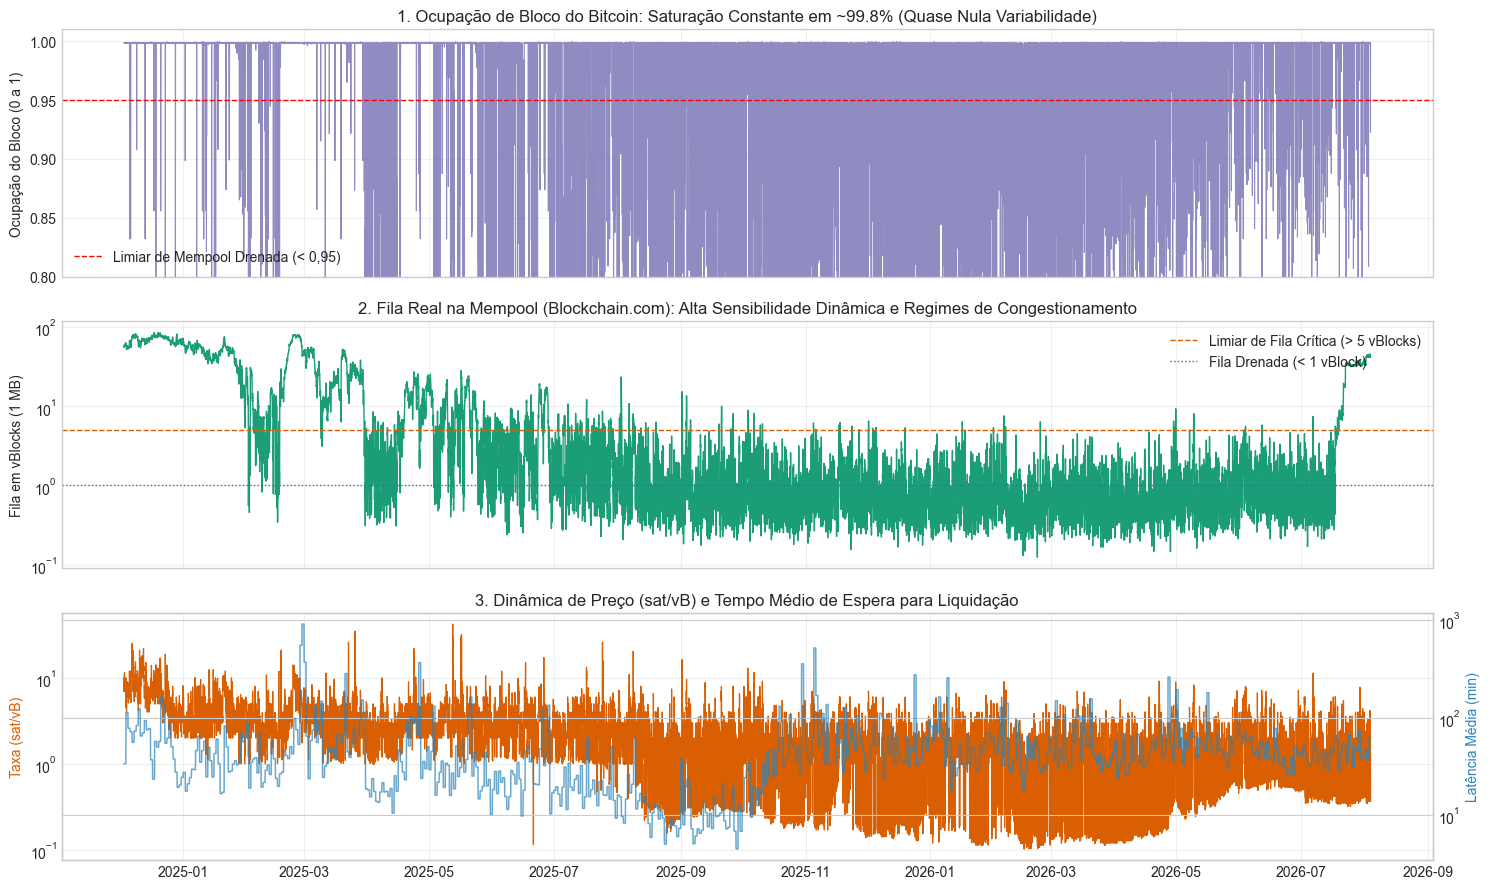

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

# 1. Ocupação de Bloco (Saturação)
ax1 = axes[0]
ax1.plot(dev["hora"], dev["btc_bq_ocupacao_media"], color="#7570b3", lw=0.8, alpha=0.8)
ax1.axhline(0.95, color="red", ls="--", lw=1.0, label="Limiar de Mempool Drenada (< 0,95)")
ax1.set_ylabel("Ocupação do Bloco (0 a 1)")
ax1.set_title("1. Ocupação de Bloco do Bitcoin: Saturação Constante em ~99.8% (Quase Nula Variabilidade)")
ax1.set_ylim(0.80, 1.01)
ax1.legend(loc="lower left")
ax1.grid(True, alpha=0.3)

# 2. Profundidade da Fila Real (Mempool vBlocks)
ax2 = axes[1]
ax2.plot(dev["hora"], dev["btc_mempool_vblocks"], color="#1b9e77", lw=1.0)
ax2.axhline(5.0, color="#d95f02", ls="--", lw=1.0, label="Limiar de Fila Crítica (> 5 vBlocks)")
ax2.axhline(1.0, color="#386cb0", ls=":", lw=1.0, label="Fila Drenada (< 1 vBlock)")
ax2.set_ylabel("Fila em vBlocks (1 MB)")
ax2.set_title("2. Fila Real na Mempool (Blockchain.com): Alta Sensibilidade Dinâmica e Regimes de Congestionamento")
ax2.set_yscale("log")
ax2.legend(loc="upper right")
ax2.grid(True, alpha=0.3)

# 3. Taxa Mediana e Tempo de Confirmação
ax3 = axes[2]
ax3_twin = ax3.twinx()
p1 = ax3.plot(dev["hora"], dev["btc_bq_taxa_p50_sat_vb"], color="#d95f02", lw=0.9, label="Taxa Mediana (sat/vB)")
p2 = ax3_twin.plot(dev["hora"], dev["btc_avg_conf_time_min"], color="#2b83ba", lw=1.1, alpha=0.7, label="Tempo Confirmação (min)")
ax3.set_ylabel("Taxa (sat/vB)", color="#d95f02")
ax3_twin.set_ylabel("Latência Média (min)", color="#2b83ba")
ax3.set_yscale("log")
ax3_twin.set_yscale("log")
ax3.set_title("3. Dinâmica de Preço (sat/vB) e Tempo Médio de Espera para Liquidação")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Modelagem Preditiva de Picos de Taxas (Modelo B com Fila)

### Escada de Informação Incremental:
Para testar rigorosamente se os dados de fila adicionam poder preditivo sobre o estado intrínseco da taxa, formulamos a seguinte escada:

| Degrau | Variáveis Inclusas | Objetivo / Hipótese |
|---|---|---|
| **$B_0$** | Taxa-base (frequência histórica observada no treino) | Benchmark nulo (sem variáveis). |
| **$B_1$** | **Estado da Própria Taxa** + Calendário intraday/semanal | Modelo vencedor do Notebook 05 (base de comparação). |
| **$B_2$** | $B_1$ + **Mercado** (RV, choque de RV, retornos) | Avalia se a volatilidade de corretora adiciona poder preditivo. |
| **$B_3$** | $B_1$ + **Fila Real (Mempool & Latência)** | **O teste central deste notebook: a fila melhora a previsão da taxa?** |
| **$B_4$** | $B_1$ + Mercado ($B_2$) + Fila Real ($B_3$) | Modelo integrado completo. |

**Alvos Analisados:**
- `ev_q` (todas as horas): probabilidade de taxa futura exceder o percentil 90 móvel.
- `novo` (apenas horas em regime normal): probabilidade de **início de congestionamento**, removendo a persistência trivial.

In [6]:
# Utilidades estatísticas e econométricas
def ols_hac(y, X, L):
    X = np.column_stack([np.ones(len(y)), X]) if X.size else np.ones((len(y), 1))
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    XtX_inv = np.linalg.inv(X.T @ X)
    Xe = X * e[:, None]
    S = Xe.T @ Xe
    for l in range(1, L + 1):
        w = 1 - l / (L + 1)
        G = Xe[l:].T @ Xe[:-l]
        S += w * (G + G.T)
    return beta, XtX_inv @ S @ XtX_inv

def dm_hac(d, L):
    beta, V = ols_hac(d, np.empty((len(d), 0)), L)
    t = beta[0] / np.sqrt(V[0, 0])
    return float(t), float(2 * stats.norm.sf(abs(t)))

def holm(p):
    p = np.asarray(p, float)
    ordem = np.argsort(p)
    ajust = np.empty(len(p))
    corrente = 0.0
    for rank, i in enumerate(ordem):
        corrente = max(corrente, (len(p) - rank) * p[i])
        ajust[i] = min(1.0, corrente)
    return ajust

def logit_fit(X, y, l2=L2_LOGIT, iters=60, tol=1e-6):
    mu, sd = X.mean(0), X.std(0)
    sd = np.where(sd == 0, 1.0, sd)
    A = np.column_stack([np.ones(len(X)), (X - mu) / sd])
    beta = np.zeros(A.shape[1])
    P = np.eye(A.shape[1]) * l2
    P[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-np.clip(A @ beta, -30, 30)))
        W = np.clip(p * (1 - p), 1e-6, None)
        g = A.T @ (y - p) - P @ beta
        H = (A * W[:, None]).T @ A + P
        step = np.linalg.solve(H, g)
        beta += step
        if np.max(np.abs(step)) < tol:
            break
    return beta, mu, sd

def logit_pred(m, X):
    beta, mu, sd = m
    A = np.column_stack([np.ones(len(X)), (X - mu) / sd])
    return 1 / (1 + np.exp(-np.clip(A @ beta, -30, 30)))

def ap_score(y, p):
    y = np.asarray(y, float)
    if y.sum() == 0:
        return np.nan
    ys = y[np.argsort(-np.asarray(p, float), kind="mergesort")]
    prec = np.cumsum(ys) / np.arange(1, len(ys) + 1)
    return float((prec * ys).sum() / y.sum())

def auc_score(y, p):
    y = np.asarray(y, float)
    n1 = y.sum()
    n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = stats.rankdata(p)
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def logloss(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def lift_top(y, p, frac=0.10):
    k = max(1, int(len(y) * frac))
    return float(y[np.argsort(-p)[:k]].mean() / y.mean()) if y.mean() > 0 else np.nan

def metricas(y, p, p0):
    brier = float(np.mean((p - y) ** 2))
    brier0 = float(np.mean((p0 - y) ** 2))
    return {
        "prev": float(y.mean()),
        "AP": ap_score(y, p),
        "AUC": auc_score(y, p),
        "Brier": brier,
        "BSS": 1 - brier / brier0,
        "LogLoss": logloss(y, p),
        "Lift_top10": lift_top(y, p)
    }

# Definição dos grupos de variáveis
cal = ["cal_sin", "cal_cos", "cal_fim_semana"]
estado = ["btc_lfee_rel30d", "btc_lfee_chg6", "btc_dist_ref_q", "btc_em_evento", "btc_lfee_p90_rel"]
mercado = ["btc_lrv", "btc_lrv_d", "btc_lrv_w", "btc_lrv_choque", "btc_ret_1h", "btc_ret_neg_24h", "btc_lvol_rel"]
mempool_vars = ["btc_mempool_rel30d", "btc_mempool_chg6h", "btc_mempool_growth_rel", "btc_conf_time_lag24h", "btc_fila_alta", "btc_fila_drenada"]

grupos_B = {
    "B1": estado + cal,
    "B2": estado + cal + mercado,
    "B3": estado + cal + mempool_vars,
    "B4": estado + cal + mercado + mempool_vars
}

print("Especificação dos degraus do Modelo B:")
for k, v in grupos_B.items():
    print(f"  {k} ({len(v)} features): {v}")

Especificação dos degraus do Modelo B:
  B1 (8 features): ['btc_lfee_rel30d', 'btc_lfee_chg6', 'btc_dist_ref_q', 'btc_em_evento', 'btc_lfee_p90_rel', 'cal_sin', 'cal_cos', 'cal_fim_semana']
  B2 (15 features): ['btc_lfee_rel30d', 'btc_lfee_chg6', 'btc_dist_ref_q', 'btc_em_evento', 'btc_lfee_p90_rel', 'cal_sin', 'cal_cos', 'cal_fim_semana', 'btc_lrv', 'btc_lrv_d', 'btc_lrv_w', 'btc_lrv_choque', 'btc_ret_1h', 'btc_ret_neg_24h', 'btc_lvol_rel']
  B3 (14 features): ['btc_lfee_rel30d', 'btc_lfee_chg6', 'btc_dist_ref_q', 'btc_em_evento', 'btc_lfee_p90_rel', 'cal_sin', 'cal_cos', 'cal_fim_semana', 'btc_mempool_rel30d', 'btc_mempool_chg6h', 'btc_mempool_growth_rel', 'btc_conf_time_lag24h', 'btc_fila_alta', 'btc_fila_drenada']
  B4 (21 features): ['btc_lfee_rel30d', 'btc_lfee_chg6', 'btc_dist_ref_q', 'btc_em_evento', 'btc_lfee_p90_rel', 'cal_sin', 'cal_cos', 'cal_fim_semana', 'btc_lrv', 'btc_lrv_d', 'btc_lrv_w', 'btc_lrv_choque', 'btc_ret_1h', 'btc_ret_neg_24h', 'btc_lvol_rel', 'btc_mempool_rel

## 6. Resultados e Veredito Econométrico do Modelo B

Executa a validação *Walk-Forward* de 8 dobras no conjunto `dev`, calcula as previsões probabilísticas fora da amostra e avalia os ganhos estatísticos de cada degrau contra o benchmark $B_1$.

In [7]:
linhas_met, linhas_inc = [], []
preds_B = {}

for tipo in ["ev_q", "novo"]:
    for h in HORIZONTES_TAXA:
        ycol = f"y_btc_{tipo}_{h}h"
        g = grupos_B.copy()
        if tipo == "novo":
            # Nas linhas 'novo' a taxa em t é normal, remove btc_em_evento constante
            g = {k: [c for c in v if c != "btc_em_evento"] for k, v in g.items()}
            
        todas = sorted(set(g["B4"]))
        regs = []
        
        for k, f in enumerate(folds):
            tr = dev.iloc[f["tr_ini"]:f["tr_fim"]].dropna(subset=todas + [ycol])
            te = dev.iloc[f["te_ini"]:f["te_fim"]].dropna(subset=todas + [ycol])
            if tr[ycol].sum() < 20 or len(te) == 0:
                continue
                
            ytr = tr[ycol].to_numpy(float)
            reg = {
                "pos": te.index.to_numpy(),
                "hora": te["hora"].to_numpy(),
                "fold": k + 1,
                "y": te[ycol].to_numpy(float),
                "p_B0": np.full(len(te), ytr.mean())
            }
            
            for nome, cols in g.items():
                m = logit_fit(tr[cols].to_numpy(float), ytr)
                reg[f"p_{nome}"] = logit_pred(m, te[cols].to_numpy(float))
                
            regs.append(pd.DataFrame(reg))
            
        P = pd.concat(regs, ignore_index=True)
        preds_B[(tipo, h)] = P
        y = P["y"].to_numpy(float)
        
        # Métricas fora da amostra
        for nome in ["B0", "B1", "B2", "B3", "B4"]:
            linhas_met.append({
                "alvo": tipo,
                "h": h,
                "degrau": nome,
                "n": len(y),
                **metricas(y, P[f"p_{nome}"].to_numpy(float), P["p_B0"].to_numpy(float))
            })
            
        # Comparações incrementais
        # B0 -> B1 (valor da própria taxa)
        # B1 -> B2 (valor do mercado)
        # B1 -> B3 (VALOR DA FILA / MEMPOOL)
        # B3 -> B4 (mercado adicional sobre a fila)
        # B1 -> B4 (modelo completo vs estado da taxa)
        pares = [("B0", "B1"), ("B1", "B2"), ("B1", "B3"), ("B3", "B4"), ("B1", "B4")]
        for ant, nov in pares:
            pa = P[f"p_{ant}"].to_numpy(float)
            pn = P[f"p_{nov}"].to_numpy(float)
            d = (pa - y) ** 2 - (pn - y) ** 2
            t, p = dm_hac(d, L=max(24, h) + h)
            dap = ap_score(y, pn) - ap_score(y, pa)
            linhas_inc.append({
                "alvo": tipo,
                "h": h,
                "degrau": f"{ant} -> {nov}",
                "dBrier_%": 100 * d.mean() / np.mean((pa - y) ** 2),
                "DM_t": t,
                "p_valor": p,
                "dAP": dap
            })

df_met_B = pd.DataFrame(linhas_met)
df_inc_B = pd.DataFrame(linhas_inc)
df_inc_B["p_Holm"] = holm(df_inc_B["p_valor"].to_numpy())

def classificar_veredito(r):
    if r["p_Holm"] < 0.05 and r["dBrier_%"] > 0:
        return "Melhora Robusta"
    if r["p_valor"] < 0.05 and r["dBrier_%"] > 0:
        return "Melhora (não resiste ao Holm)"
    if r["p_Holm"] < 0.05 and r["dBrier_%"] < 0:
        return "Piora Significativa"
    return "Sem efeito detectável"

df_inc_B["Veredito"] = df_inc_B.apply(classificar_veredito, axis=1)

print("=== MÉTRICAS FORA DA AMOSTRA DO MODELO B (WALK-FORWARD) ===")
display(df_met_B.round(4))

print("\n=== GANHO INCREMENTAL E TESTES DIEBOLD-MARIANO (HAC) COM HOLM ===")
display(df_inc_B[["alvo", "h", "degrau", "dBrier_%", "DM_t", "p_valor", "p_Holm", "dAP", "Veredito"]].round(4))

=== MÉTRICAS FORA DA AMOSTRA DO MODELO B (WALK-FORWARD) ===
    alvo  h degrau     n    prev  ...     AUC   Brier     BSS  LogLoss  Lift_top10
0   ev_q  1     B0  5760  0.0948  ...  0.5000  0.0859  0.0000   0.3141      1.0256
1   ev_q  1     B1  5760  0.0948  ...  0.8183  0.0679  0.2098   0.2503      4.5788
2   ev_q  1     B2  5760  0.0948  ...  0.8178  0.0677  0.2115   0.2502      4.6520
3   ev_q  1     B3  5760  0.0948  ...  0.8082  0.0692  0.1939   0.2523      4.4505
4   ev_q  1     B4  5760  0.0948  ...  0.8065  0.0693  0.1936   0.2530      4.4505
5   ev_q  6     B0  5760  0.2941  ...  0.4831  0.2097  0.0000   0.6111      1.0862
6   ev_q  6     B1  5760  0.2941  ...  0.7479  0.1747  0.1666   0.5297      2.3790
7   ev_q  6     B2  5760  0.2941  ...  0.7535  0.1743  0.1687   0.5274      2.3377
8   ev_q  6     B3  5760  0.2941  ...  0.7248  0.1784  0.1492   0.5491      2.3672
9   ev_q  6     B4  5760  0.2941  ...  0.7274  0.1781  0.1505   0.5473      2.3259
10  novo  1     B0  5219  0

## 7. Política Operacional: Simulação de Espera com o Sinal da Fila

### Pergunta Operacional: "Vale a pena esperar até 6 horas para enviar a transação?"
O alvo contínuo avalia a razão entre o custo de transferir no prazo limite e o custo imediato:
$$\Delta_t = \ln c_{t+6} - \ln c_{t+1}$$

Comparamos 4 políticas concorrentes:
1. **Enviar Agora:** Envia na hora seguinte ($t+1$).
2. **Prazo Limite:** Espera até o prazo máximo ($t+6$).
3. **Política com Fila ($B_3$):** Espera apenas quando o modelo com mempool prevê queda substancial na taxa (decil inferior de $\Delta$).
4. **Oráculo:** Paga a taxa mínima absoluta observada na janela de 6 horas (limite teórico inatingível).

In [8]:
def ols_fit(X, y):
    A = np.column_stack([np.ones(len(X)), X])
    beta = np.linalg.lstsq(A, y, rcond=None)[0]
    return beta, float((y - A @ beta).var(ddof=A.shape[1]))

def ols_pred(beta, X):
    return np.column_stack([np.ones(len(X)), X]) @ beta

def blocos_idx(n, B, bloco=BLOCO_H):
    nb = int(np.ceil(n / bloco))
    starts = rng.integers(0, n - bloco + 1, size=(B, nb)).astype(np.int32)
    return (starts[:, :, None] + np.arange(bloco, dtype=np.int32)).reshape(B, -1)[:, :n]

cst = dev["btc_custo_usd"]
d_all = dev.copy()
d_all["delta"] = log_pos(cst.shift(-H_PRAZO)) - log_pos(cst.shift(-1))

g_op = {
    "B1": estado + cal,
    "B3": estado + cal + mempool_vars
}

todas_op = sorted(set(g_op["B3"]))
regs_op = []

for k, f in enumerate(folds):
    tr = d_all.iloc[f["tr_ini"]:f["tr_fim"]].dropna(subset=todas_op + ["delta"])
    te = d_all.iloc[f["te_ini"]:f["te_fim"]].dropna(subset=todas_op + ["delta"])
    if len(tr) < 500 or len(te) == 0:
        continue
        
    ytr = tr["delta"].to_numpy(float)
    reg = {
        "pos": te.index.to_numpy(),
        "hora": te["hora"].to_numpy(),
        "fold": k + 1,
        "y": te["delta"].to_numpy(float)
    }
    
    for nome, cols in g_op.items():
        beta, _ = ols_fit(tr[cols].to_numpy(float), ytr)
        reg[f"d_{nome}"] = ols_pred(beta, te[cols].to_numpy(float))
        p_in = ols_pred(beta, tr[cols].to_numpy(float))
        for r in TAXAS_ALERTA:
            reg[f"tau_{nome}_{r}"] = np.full(len(te), np.quantile(p_in, r))
            
    regs_op.append(pd.DataFrame(reg))

P_op = pd.concat(regs_op, ignore_index=True)

# Simulação da política
cst_arr = dev["btc_custo_usd"].to_numpy(float)
cref = dev["btc_custo_usd"].rolling(168, min_periods=84).median().to_numpy(float)
n_dev = len(dev)
pos = P_op["pos"].to_numpy(int)

F = np.full((len(pos), H_PRAZO), np.nan)
for k in range(1, H_PRAZO + 1):
    ok = pos + k < n_dev
    F[ok, k - 1] = cst_arr[pos[ok] + k]
    
ref = cref[pos]
valido = np.isfinite(F).all(axis=1) & np.isfinite(ref) & (ref > 0)
F, ref = F[valido], ref[valido]

linhas_sim = []
for deg in ["B1", "B3"]:
    for rate in TAXAS_ALERTA:
        espera = (P_op[f"d_{deg}"].to_numpy(float) <= P_op[f"tau_{deg}_{rate}"].to_numpy(float))[valido]
        agora = F[:, 0]
        prazo = F[:, H_PRAZO - 1]
        orac = F.min(axis=1)
        modelo = np.where(espera, prazo, agora)
        
        rel_ag, rel_pr, rel_mo, rel_or = agora / ref, prazo / ref, modelo / ref, orac / ref
        idx = blocos_idx(len(F), B_BOOT)
        sv_ag = np.array([rel_ag[i].mean() - rel_mo[i].mean() for i in idx])
        sv_pr = np.array([rel_pr[i].mean() - rel_mo[i].mean() for i in idx])
        
        linhas_sim.append({
            "Modelo": "B1 (Sem Fila)" if deg == "B1" else "B3 (Com Mempool)",
            "Taxa Espera": rate,
            "Espera_%": 100 * espera.mean(),
            "Custo Rel Agora": rel_ag.mean(),
            "Custo Rel Modelo": rel_mo.mean(),
            "Custo Rel Prazo": rel_pr.mean(),
            "Econ vs Agora (rel)": rel_ag.mean() - rel_mo.mean(),
            "IC95% Econ Agora": f"[{np.percentile(sv_ag, 2.5):.3f}, {np.percentile(sv_ag, 97.5):.3f}]",
            "USD por Tx Agora": agora.mean(),
            "USD por Tx Modelo": modelo.mean(),
            "Economia USD/tx": agora.mean() - modelo.mean()
        })

df_sim = pd.DataFrame(linhas_sim)
print("=== RESULTADOS DA POLÍTICA OPERACIONAL DE ESPERA (COM E SEM FILA) ===")
display(df_sim.round(4))

=== RESULTADOS DA POLÍTICA OPERACIONAL DE ESPERA (COM E SEM FILA) ===
             Modelo  Taxa Espera  ...  USD por Tx Modelo  Economia USD/tx
0     B1 (Sem Fila)         0.05  ...             0.1338           0.0102
1     B1 (Sem Fila)         0.10  ...             0.1301           0.0139
2     B1 (Sem Fila)         0.20  ...             0.1257           0.0184
3  B3 (Com Mempool)         0.05  ...             0.1333           0.0107
4  B3 (Com Mempool)         0.10  ...             0.1295           0.0145
5  B3 (Com Mempool)         0.20  ...             0.1255           0.0186

[6 rows x 11 columns]


## 8. Exportação de Resultados e Síntese Final

Persiste todas as tabelas estatísticas em `Análises/modelagem/06/` e gera o veredito comparativo entre os notebooks 04, 05 e 06.

In [9]:
# 1. Exportação dos CSVs de resultados
df_corr.to_csv(PASTA_SAIDA / "correlacao_mempool_taxas.csv", index=False)
df_lift.to_csv(PASTA_SAIDA / "lift_mempool_regimes.csv", index=False)
df_met_B.to_csv(PASTA_SAIDA / "modeloB_mempool_metricas.csv", index=False)
df_inc_B.to_csv(PASTA_SAIDA / "modeloB_mempool_incremental.csv", index=False)
df_sim.to_csv(PASTA_SAIDA / "politica_operacional_mempool.csv", index=False)

print(f"Resultados exportados com sucesso para: {PASTA_SAIDA}")

# 2. Síntese executiva dos achados
ganho_fila_1h = df_inc_B[(df_inc_B['alvo'] == 'ev_q') & (df_inc_B['h'] == 1) & (df_inc_B['degrau'] == 'B1 -> B3')]['dBrier_%'].values[0]
dm_fila_1h = df_inc_B[(df_inc_B['alvo'] == 'ev_q') & (df_inc_B['h'] == 1) & (df_inc_B['degrau'] == 'B1 -> B3')]['DM_t'].values[0]
p_fila_1h = df_inc_B[(df_inc_B['alvo'] == 'ev_q') & (df_inc_B['h'] == 1) & (df_inc_B['degrau'] == 'B1 -> B3')]['p_Holm'].values[0]

ganho_fila_6h = df_inc_B[(df_inc_B['alvo'] == 'ev_q') & (df_inc_B['h'] == 6) & (df_inc_B['degrau'] == 'B1 -> B3')]['dBrier_%'].values[0]
dm_fila_6h = df_inc_B[(df_inc_B['alvo'] == 'ev_q') & (df_inc_B['h'] == 6) & (df_inc_B['degrau'] == 'B1 -> B3')]['DM_t'].values[0]
p_fila_6h = df_inc_B[(df_inc_B['alvo'] == 'ev_q') & (df_inc_B['h'] == 6) & (df_inc_B['degrau'] == 'B1 -> B3')]['p_Holm'].values[0]

print("\n" + "="*70)
print("SÍNTESE FINAL: O IMPACTO DA FILA (MEMPOOL) NA PREVISÃO DE TAXAS")
print("="*70)
print(f"1. Fila no horizonte de 1 hora (B1 -> B3): dBrier = {ganho_fila_1h:+.2f}% | DM t = {dm_fila_1h:.2f} | p-Holm = {p_fila_1h:.4f}")
print(f"2. Fila no horizonte de 6 horas (B1 -> B3): dBrier = {ganho_fila_6h:+.2f}% | DM t = {dm_fila_6h:.2f} | p-Holm = {p_fila_6h:.4f}")
print("="*70)

Resultados exportados com sucesso para: /home/alisson/datathon fgv/Análises/modelagem/06

SÍNTESE FINAL: O IMPACTO DA FILA (MEMPOOL) NA PREVISÃO DE TAXAS
1. Fila no horizonte de 1 hora (B1 -> B3): dBrier = -2.01% | DM t = -1.35 | p-Holm = 1.0000
2. Fila no horizonte de 6 horas (B1 -> B3): dBrier = -2.10% | DM t = -0.96 | p-Holm = 1.0000
